# Lab 3

## 0. Configurari


In [7]:
import random
import re
import zipfile
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from skimage import data as skimage_data

plt.rcParams["figure.dpi"] = 80

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
IMAGE_PATH = "/content/lab3_photos/img1.png"
DATASET_DIR = "/content/lab3_photos"
DATASET_ZIP = "/content/IIT_DB_selectie.ZIP"
WORK_DIR = Path("lab3_output")
SEED = 0
VISUAL_DETECTOR = "SIFT"
WORK_DIR.mkdir(exist_ok=True)

## A. Functii ajutatoare


### A1. Constante si structuri de date
- SENSITIVITY_LEVELS defineste cate 4 praguri de la strict la permisiv pentru fiecare detector, permitand codului sa isi ajusteze automat sensibilitatea in functie de claritatea imaginii. Pe o poza clara se foloseste primul nivel (strict) pentru a pastra doar puncte de calitate fara zgomot, iar pe o poza puternic blurata pragul coboara treptat ca detectorul sa nu returneze 0 puncte si sa nu blocheze etapele urmatoare.

- DETECTOR_FACTORIES este un dictionar care asociaza numele fiecarui algoritm (SIFT, ORB, BRISK, AKAZE, KAZE) cu o functie lambda ce instantiaza pe loc detectorul OpenCV configurat cu pragul de sensibilitate primit.

- MATCHING_METHODS este dictionarul care asociaza numele procedurilor de potrivire ("BF" si "kNN") cu functiile lor de calcul, permitand apelarea lor uniforma in pipeline.

- Features(keypoints, descriptors): Este o structura care grupeaza rezultatul extractiei de trasaturi pentru o imagine si un anumit detector. Aceasta pastreaza mereu sincronizate tuplul punctelor cheie (keypoints, cu coordonate, scara si orientare) si matricea lor de descriptori numerici (descriptors), prevenind modificarea accidentala a datelor intre etapele de vizualizare si matching.

- Sample(name, label, gray): Incapsuleaza o fotografie individuala din setul de date (train sau test) folosit in Partea 2 pentru recunoasterea locatiilor. Reuneste intr-un singur obiect numele fisierului (name), eticheta reala a clasei (label) si matricea imaginii in tonuri de gri (gray), simplificand votarea candidatilor si calculul acuratetii.

In [10]:
DETECTOR_NAMES = ("HARRIS", "SIFT", "SURF", "ORB", "BRISK", "AKAZE", "KAZE")
MATCHING_METHODS = ("bf", "knn")
RATIO_THRESHOLD = 0.75
GRID_SIZE = 8
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

SENSITIVITY_LEVELS = {
    "HARRIS": (0.01, 0.005, 0.001, 0.0001),
    "SIFT": (0.04, 0.02, 0.01, 0.005),
    "SURF": (400, 200, 100, 50),
    "ORB": (20, 10, 5, 1),
    "BRISK": (30, 20, 10, 5),
    "AKAZE": (0.001, 0.0005, 0.0001, 0.00001),
    "KAZE": (0.001, 0.0005, 0.0001, 0.00001),
}

DETECTOR_FACTORIES = {
    "SIFT": lambda value: cv2.SIFT_create(contrastThreshold=value),
    "SURF": lambda value: cv2.xfeatures2d.SURF_create(hessianThreshold=value),
    "ORB": lambda value: cv2.ORB_create(nfeatures=1500, fastThreshold=int(value)),
    "BRISK": lambda value: cv2.BRISK_create(thresh=int(value)),
    "AKAZE": lambda value: cv2.AKAZE_create(threshold=value),
    "KAZE": lambda value: cv2.KAZE_create(threshold=value),
}


@dataclass(frozen=True)
class Features:
    keypoints: tuple
    descriptors: np.ndarray


@dataclass(frozen=True)
class Sample:
    name: str
    label: str
    gray: np.ndarray

### A2. Detectie si descriptori

load_gray(path)
- functie utilizata pentru conversia in grasycale

harris_keypoints(gray, relative_threshold, ...)
- OpenCv nu are o functie pentru Harris asa ca o facem de mana.

-> prima oara dam pixelilor o nota ca sa vedem cat de mult seamana cu un colt

-> se uita in jurul fiecarui pixel, intr un patrat de 5x5 si il pastreaza pe cel cu o nota mai mare

-> luam coordonatele, le ordonam si pastram maxim 2000

-> returnam tupla cu punctele

is_detector_available(name) / available_detectors(names)
- incearca sa construiasca detectorul. Daca avem eroare inseamna ca metoda nu exista in aceasta instalare. Se afiseaza un mesaj o singura data si se continua.

detect_and_describe(name, gray, level)
- realizeaza detectia manuala pentru harris, iar pentru ceilalti algorimi apeleaza functia din biblioteca de python

extract_with_level, extract_features(name, gray), extract_all_features(names, gray)
- incearca nivelurile 0-3 din SENSITIVITY_LEVELS si returneaza primul rezultat nevid (si nivelul folosit). Daca niciunul nu da keypoints, afiseaza un mesaj si returneaza `None`. `extract_all_features` ruleaza toate metodele si elimina rezultatele `None`.
- parametrii stricti se incearca primii, pentru ca relaxarea adauga keypoints zgomotoase.

In [11]:
def load_gray(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Nu s-a putut citi imaginea: {path}")
    return image


def harris_keypoints(
    gray: np.ndarray,
    relative_threshold: float,
    block_size: int = 2,
    aperture_size: int = 3,
    harris_k: float = 0.04,
    keypoint_size: float = 8.0,
    max_points: int = 2000,
) -> tuple:
    response = cv2.cornerHarris(np.float32(gray), block_size, aperture_size, harris_k)
    is_local_maximum = response == cv2.dilate(response, np.ones((5, 5), np.uint8))
    is_strong = response > relative_threshold * max(float(response.max()), 0.0)
    rows, cols = np.nonzero(is_local_maximum & is_strong)
    strongest_first = np.argsort(response[rows, cols])[::-1][:max_points]
    return tuple(
        cv2.KeyPoint(float(cols[i]), float(rows[i]), keypoint_size)
        for i in strongest_first
    )


def is_detector_available(name: str) -> bool:
    if name == "HARRIS":
        return True
    try:
        DETECTOR_FACTORIES[name](SENSITIVITY_LEVELS[name][0])
    except (AttributeError, cv2.error):
        return False
    return True


def available_detectors(names: tuple = DETECTOR_NAMES) -> list:
    usable = []
    for name in names:
        if is_detector_available(name):
            usable.append(name)
        else:
            print(f"{name}: indisponibila in OpenCV, se sare peste ea")
    return usable


def detect_and_describe(name: str, gray: np.ndarray, level: int):
    value = SENSITIVITY_LEVELS[name][level]
    if name == "HARRIS":
        keypoints = harris_keypoints(gray, value)
        if not keypoints:
            return None
        keypoints, descriptors = cv2.SIFT_create().compute(gray, keypoints)
    else:
        keypoints, descriptors = DETECTOR_FACTORIES[name](value).detectAndCompute(gray, None)
    if descriptors is None or len(keypoints) == 0:
        return None
    return Features(tuple(keypoints), descriptors)


def extract_with_level(name: str, gray: np.ndarray) -> tuple:
    for level in range(len(SENSITIVITY_LEVELS[name])):
        features = detect_and_describe(name, gray, level)
        if features is not None:
            return features, level
    return None, None


def extract_features(name: str, gray: np.ndarray):
    features, _ = extract_with_level(name, gray)
    if features is None:
        print(f"{name}: niciun keypoint gasit nici la sensibilitate maxima")
    return features


def extract_all_features(names: list, gray: np.ndarray) -> dict:
    extracted = {name: extract_features(name, gray) for name in names}
    return {name: features for name, features in extracted.items() if features is not None}

### A3. Matching

norm_type_for(descriptors)
- Alege formula matematica de calcul al distantei dintre doua amprente numerice (descriptori), in functie de formatul lor: cu cat distanta este mai mica, cu atat zonele arata mai identic. Foloseste NORM_HAMMING (numara cati biti difera intre doua siruri de 0 si 1) pentru descriptorii binari (uint8, ca la ORB/BRISK) si NORM_L2 (distanta euclidiana clasica) pentru cei cu numere reale (float32, ca la SIFT/KAZE).

brute_force_matches(query, train)
- Ia fiecare punct din prima poza si il compara matematic cu absolut toate punctele din a doua poza pentru a-i gasi cel mai apropiat vecin. Optiunea crossCheck=True impune regula alegerii reciproce: perechea (A, B) este validata doar daca B este cel mai bun candidat pentru A si, verificand invers, A este tot cel mai bun candidat pentru B. Daca B prefera un alt punct din prima poza, potrivirea este respinsa (totusi, pe zone taiate complet din a doua poza, pot aparea uneori perechi reciproce false in fundal).

knn_matches(query, train, ratio)
- Cauta cei mai buni 2 candidati (k=2, locul 1 si locul 2) din a doua poza pentru fiecare punct din prima poza si aplica testul raportului (Lowe's Ratio Test): pastreaza potrivirea doar daca locul 1 este detasat mult mai bun decat locul 2 (distanta_1 < ratio * distanta_2, implicit 0.75). Daca doi candidati au distante foarte apropiate (cum se intampla pe texturi repetitive precum caramizi, ferestre sau frunze), algoritmul detecteaza riscul de confuzie si respinge potrivirea, eliminand mult mai eficient liniile gresite.

find_matches(method, query, train)
- Actioneaza ca un dispecer care primeste numele metodei ("bf" sau "knn"), o cauta in dictionarul MATCHERS si ruleaza functia corespunzatoare pe matricile de descriptori ale celor doua seturi de Features.

count_matches(method, query, train)
- Apeleaza find_matches si returneaza strict numarul total de perechi valide gasite, fiind folosita in tabelele de evaluare din Partea 1 si la calculul scorului de votare din Partea 2.

In [12]:
def norm_type_for(descriptors: np.ndarray) -> int:
    return cv2.NORM_HAMMING if descriptors.dtype == np.uint8 else cv2.NORM_L2


def brute_force_matches(query: np.ndarray, train: np.ndarray) -> list:
    matcher = cv2.BFMatcher(norm_type_for(query), crossCheck=True)
    return list(matcher.match(query, train))


def knn_matches(query: np.ndarray, train: np.ndarray, ratio: float = RATIO_THRESHOLD) -> list:
    if len(train) < 2:
        return []
    matcher = cv2.BFMatcher(norm_type_for(query))
    neighbour_pairs = matcher.knnMatch(query, train, k=2)
    return [
        pair[0]
        for pair in neighbour_pairs
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance
    ]


MATCHERS = {"bf": brute_force_matches, "knn": knn_matches}


def find_matches(method: str, query: Features, train: Features) -> list:
    return MATCHERS[method](query.descriptors, train.descriptors)


def count_matches(method: str, query: Features, train: Features) -> int:
    return len(find_matches(method, query, train))

### A4. Transformarile imaginii (1c, 1d, 1e)

blur_image(gray, kind, kernel_size)
- Aplica un efect de incetosare pe poza folosind o fereastra patrata ("lupa") de kernel_size x kernel_size pixeli.
- Lupa se plimba peste fiecare pixel si il inlocuieste cu media vecinilor prinsi in patrat. Daca kind == "mean" (cv2.blur), toti vecinii au greutate egala (blur uniform), altfel (cv2.GaussianBlur), pixelii din mijloc conteaza mai mult decat cei de pe margini. Kernelii mai mari sterg colturile fine ca sa testeze ce detectori supravietuiesc pierderii de detalii.

rotate_image(gray, angle_degrees)
- Roteste imaginea in sens invers acelor de ceasornic cu unghiul cerut, marind automat dimensiunea cadrului final ca sa nu se taie colturile pozei.
- Functia cv2.getRotationMatrix2D calculeaza matricea de rotatie in jurul vechiului centru (width / 2, height / 2). Daca am pastra dimensiunile vechi, colturile dreptunghiului inclinat ar iesi in afara si ar fi taiate. De aceea, codul extrage cos si sin direct din matrice si calculeaza noua latime si inaltime (new_width, new_height) ale dreptunghiului incadrator. Apoi, adauga diferenta new_width / 2 - center[0] si new_height / 2 - center[1] la componentele de translatie (matrix[0, 2] si matrix[1, 2]), mutand poza rotita fix in mijlocul noului cadru mai mare.

add_gaussian_noise(gray, sigma, seed=0)
- Adauga "pureci" peste poza pentru a simula o fotografie facuta pe intuneric cu ISO mare.
- Pixelii unei imagini sunt stocati ca uint8 (numere intregi strict intre 0 si 255). Daca ai aduna zgomot direct peste uint8, valorile care depasesc intervalul ar face "overflow" circular (de exemplu, 250 + 10 s-ar transforma in 4, facand un pixel alb sa devina brusc negru). Convetim mai intai poza in numere reale (np.float32), aduna zgomotul gaussian, taie valorile iesite din interval la marginile 0 si 255 cu np.clip(...) si abia apoi revine la uint8. Parametrul fix seed=0 garanteaza ca se genereaza exact acelasi tipar de zgomot la fiecare rulare, pentru o comparatie corecta intre algoritmi.

build_blur_variants(gray)
- Returneaza un dictionar cu 6 versiuni blurate ale pozei de referinta, combinand cele doua tipuri de blur ("mean" si "gaussian") cu trei dimensiuni progresive de kernel (3x3, 7x7 si 15x15).

build_rotation_variants(gray)
- Returneaza un dictionar cu 4 versiuni rotite ale pozei la unghiurile 15, 45, 90 si 180 de grade, pentru a testa daca detectorii si descriptorii raman stabili cand camera este inclinata.

build_noise_variants(gray)
- Returneaza un dictionar cu 4 versiuni ale pozei afectate de zgomot din ce in ce mai puternic (sigma = 5, 15, 30, 60), pentru a vedea pragul la care fiecare algoritm incepe sa dea rateuri.

In [13]:
def blur_image(gray: np.ndarray, kind: str, kernel_size: int) -> np.ndarray:
    if kind == "mean":
        return cv2.blur(gray, (kernel_size, kernel_size))
    return cv2.GaussianBlur(gray, (kernel_size, kernel_size), 0)


def rotate_image(gray: np.ndarray, angle_degrees: float) -> np.ndarray:
    height, width = gray.shape
    center = (width / 2, height / 2)
    matrix = cv2.getRotationMatrix2D(center, angle_degrees, 1.0)
    cos, sin = abs(matrix[0, 0]), abs(matrix[0, 1])
    new_width = int(round(height * sin + width * cos))
    new_height = int(round(height * cos + width * sin))
    matrix[0, 2] += new_width / 2 - center[0]
    matrix[1, 2] += new_height / 2 - center[1]
    return cv2.warpAffine(gray, matrix, (new_width, new_height))


def add_gaussian_noise(gray: np.ndarray, sigma: float, seed: int = 0) -> np.ndarray:
    rng = np.random.default_rng(seed)
    noisy = gray.astype(np.float32) + rng.normal(0.0, sigma, gray.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)


def build_blur_variants(gray: np.ndarray) -> dict:
    return {
        f"{kind} blur {size}x{size}": blur_image(gray, kind, size)
        for kind in ("mean", "gaussian")
        for size in (3, 7, 15)
    }


def build_rotation_variants(gray: np.ndarray) -> dict:
    return {f"rotation {angle} deg": rotate_image(gray, angle) for angle in (15, 45, 90, 180)}


def build_noise_variants(gray: np.ndarray) -> dict:
    return {f"noise sigma={sigma}": add_gaussian_noise(gray, sigma) for sigma in (5, 15, 30, 60)}

create_axes_grid(count, columns=3)
- Construieste automat o grila de subplot-uri matplotlib dimensionata pentru count grafice si ascunde casutele ramase libere la final.
- Expresia -(-count // columns) face rotunjirea in sus fara a importa biblioteca math. Parametrul squeeze=False obliga matplotlib sa returneze axele mereu ca matrice 2D (chiar si cand ai un singur rand), astfel incat .ravel() sa functioneze fara erori, iar unused_axis.axis("off") sterge chenarele goale de pe ultimul rand incomplet.

show_and_save(figure, filename)
- Ajusteaza spatierea dintre grafice, salveaza figura in folderul de lucru (WORK_DIR) si o afiseaza in notebook.

draw_keypoints(gray, features)
- Deseneaza punctele cheie detectate peste imaginea alb-negru cu verde si converteste poza in format RGB pentru afisare.
- Flag-ul DRAW_RICH_KEYPOINTS  deseneaza cercuri proportionale cu scara la care a fost gasit punctul si o raza care arata orientarea (unghiul) lui.

plot_keypoints(gray, features_by_name, filename)
- Creeaza un colaj comparativ cu cate o imagine adnotata pentru fiecare detector activ, afisand in titlu numarul total de puncte gasite, apoi salveaza figura pe disc.

keypoints_per_region(keypoints, image_shape, grid_size=GRID_SIZE)
- Imparte suprafata imaginii intr-o grila de 8x8 sectoare egale si numara cate puncte cheie cad in fiecare casuta, returnand o matrice de frecvente.
- Coordonatele (x, y) sunt proiectate proportional in indici de la 0 la 7, iar min(..., grid_size - 1) previne IndexError daca un keypoint pica fix pe marginea din dreapta sau de jos a imaginii (unde impartirea ar da 8).

plot_region_counts(image_shape, features_by_name, filename)
- Transforma matricea 8x8 a fiecarui detector intr-o harta de caldura (heatmap) cu paleta "viridis" si scrie cu alb valoarea numerica exacta in centrul fiecarui patrat.
- In axis.text(column, row, ...), coordonatele sunt puse in ordinea (coloana, rand) deoarece in graficele 2D coloana reprezinta axa orizontala X, iar randul reprezinta axa verticala Y.

distribution_table(image_shape, features_by_name)
- Construieste un tabel statistic pandas din matricea 8x8 pentru a masura obiectiv cat de uniform sunt imprastiate punctele (total, regiuni goale, maxim intr-o regiune si coeficientul de variatie std / mean).
- Coeficientul de variatie imparte deviatia standard la medie pentru a obtine un scor relativ: astfel poti compara corect un detector cu 300 de puncte (HARRIS) cu unul cu 2000 de puncte (ORB), vazand care dintre ele isi ingramadeste punctele intr-o singura zona.

plot_image_grid(images, filename, columns=4)
- Afiseaza o colectie de imagini alb-negru (cum sunt variantele cu blur, zgomot sau rotatie) intr-o grila cu 4 coloane si salveaza colajul rezultat.

In [14]:
def create_axes_grid(count: int, columns: int = 3) -> tuple:
    rows = -(-count // columns)
    figure, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4.5 * rows), squeeze=False)
    flat_axes = list(axes.ravel())
    for unused_axis in flat_axes[count:]:
        unused_axis.axis("off")
    return figure, flat_axes[:count]


def show_and_save(figure, filename: str) -> None:
    figure.tight_layout()
    figure.savefig(WORK_DIR / filename, dpi=110)
    plt.show()
    plt.close(figure)


def draw_keypoints(gray: np.ndarray, features: Features) -> np.ndarray:
    drawn = cv2.drawKeypoints(
        gray,
        features.keypoints,
        None,
        color=(0, 255, 0),
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
    )
    return cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB)


def plot_keypoints(gray: np.ndarray, features_by_name: dict, filename: str) -> None:
    figure, axes = create_axes_grid(len(features_by_name))
    for axis, (name, features) in zip(axes, features_by_name.items()):
        axis.imshow(draw_keypoints(gray, features))
        axis.set_title(f"{name}: {len(features.keypoints)} keypoints")
        axis.axis("off")
    show_and_save(figure, filename)


def keypoints_per_region(keypoints: tuple, image_shape: tuple, grid_size: int = GRID_SIZE) -> np.ndarray:
    height, width = image_shape
    counts = np.zeros((grid_size, grid_size), dtype=int)
    for keypoint in keypoints:
        column = min(int(keypoint.pt[0] * grid_size / width), grid_size - 1)
        row = min(int(keypoint.pt[1] * grid_size / height), grid_size - 1)
        counts[row, column] += 1
    return counts


def plot_region_counts(image_shape: tuple, features_by_name: dict, filename: str) -> None:
    figure, axes = create_axes_grid(len(features_by_name))
    for axis, (name, features) in zip(axes, features_by_name.items()):
        counts = keypoints_per_region(features.keypoints, image_shape)
        axis.imshow(counts, cmap="viridis")
        axis.set_title(f"{name}: keypoints per regiune 8x8")
        axis.set_xticks([])
        axis.set_yticks([])
        for row in range(GRID_SIZE):
            for column in range(GRID_SIZE):
                axis.text(column, row, counts[row, column], ha="center", va="center", color="white", fontsize=7)
    show_and_save(figure, filename)


def distribution_table(image_shape: tuple, features_by_name: dict) -> pd.DataFrame:
    rows = []
    for name, features in features_by_name.items():
        counts = keypoints_per_region(features.keypoints, image_shape)
        mean = counts.mean()
        rows.append(
            {
                "detector": name,
                "total": int(counts.sum()),
                "empty_regions": int((counts == 0).sum()),
                "max_in_region": int(counts.max()),
                "coeff_variation": round(float(counts.std() / mean), 2) if mean > 0 else 0.0,
            }
        )
    return pd.DataFrame(rows).set_index("detector")


def plot_image_grid(images: dict, filename: str, columns: int = 4) -> None:
    figure, axes = create_axes_grid(len(images), columns)
    for axis, (label, image) in zip(axes, images.items()):
        axis.imshow(image, cmap="gray", vmin=0, vmax=255)
        axis.set_title(label, fontsize=9)
        axis.axis("off")
    show_and_save(figure, filename)

### A6. (1c, 1d, 1e)

draw_match_image
- sorteaza potrivirile dupa distanta, pastreaza cele mai bune `limit` (40, ca imaginea sa ramana lizibila) si le deseneaza cu `cv2.drawMatches`. Imaginea de referinta este in stanga, versiunea procesata in dreapta. Numarul real de potriviri se raporteaza separat, in titlu.

plot_match_gallery
- pentru **fiecare** versiune procesata, o figura cu potrivirile BF si kNN fata de referinta.

evaluate_variants
- pentru fiecare varianta si fiecare metoda: extrage keypoints, numara potrivirile BF si kNN fata de original Caracteristicile originalului se calculeaza o singura data si se reutilizeaza.

pivot_matches(table, method)
- tabel variante x metode pentru o procedura.

plot_match_curves
- numarul de potriviri pe variante, cate o linie pe metoda, pentru BF si pentru kNN.

In [15]:
def draw_match_image(ref_gray, ref_features: Features, var_gray, var_features: Features, matches: list, limit: int = 40) -> np.ndarray:
    best = sorted(matches, key=lambda match: match.distance)[:limit]
    canvas = cv2.drawMatches(
        ref_gray,
        ref_features.keypoints,
        var_gray,
        var_features.keypoints,
        best,
        None,
        matchColor=(0, 255, 0),
        singlePointColor=(255, 0, 0),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


def slugify(text: str) -> str:
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


def plot_match_gallery(detector: str, ref_gray, ref_features: Features, variants: dict, prefix: str) -> None:
    for label, image in variants.items():
        variant = extract_features(detector, image)
        figure, axes = plt.subplots(1, len(MATCHING_METHODS), figsize=(7 * len(MATCHING_METHODS), 4.5))
        for axis, method in zip(axes, MATCHING_METHODS):
            axis.axis("off")
            if variant is None:
                axis.set_title(f"{label} | {method}: fara keypoints", fontsize=9)
                continue
            matches = find_matches(method, ref_features, variant)
            axis.imshow(draw_match_image(ref_gray, ref_features, image, variant, matches))
            axis.set_title(
                f"{detector} | {label} | {method}: {len(matches)} potriviri "
                f"(ref {len(ref_features.keypoints)} kp, var {len(variant.keypoints)} kp)",
                fontsize=9,
            )
        show_and_save(figure, f"{prefix}_{slugify(label)}.png")


def evaluate_variants(original_features: dict, variants: dict) -> pd.DataFrame:
    rows = []
    for label, image in variants.items():
        for name, original in original_features.items():
            variant = extract_features(name, image)
            row = {
                "variant": label,
                "detector": name,
                "kp_original": len(original.keypoints),
                "kp_variant": 0 if variant is None else len(variant.keypoints),
            }
            for method in MATCHING_METHODS:
                row[method] = 0 if variant is None else count_matches(method, original, variant)
            rows.append(row)
    return pd.DataFrame(rows)


def pivot_matches(table: pd.DataFrame, method: str) -> pd.DataFrame:
    pivot = table.pivot(index="variant", columns="detector", values=method)
    return pivot.loc[table["variant"].unique()]


def plot_match_curves(table: pd.DataFrame, title: str, filename: str) -> None:
    figure, axes = plt.subplots(1, len(MATCHING_METHODS), figsize=(7 * len(MATCHING_METHODS), 4.8))
    for axis, method in zip(axes, MATCHING_METHODS):
        pivot = pivot_matches(table, method)
        positions = range(len(pivot.index))
        for detector in pivot.columns:
            axis.plot(positions, pivot[detector], marker="o", label=detector)
        axis.set_xticks(list(positions))
        axis.set_xticklabels(pivot.index, rotation=45, ha="right", fontsize=8)
        axis.set_title(f"{title} - {method}")
        axis.set_ylabel("keypoints potrivite")
        axis.legend(fontsize=8)
    show_and_save(figure, filename)

### A7. Functii pentru partea a doua (Clasificare si Evaluare)

infer_label
 - Se uita la calea imaginii ca sa-i gaseasca eticheta. Daca poza e intr-un subfolder, numele acelui folder devine direct eticheta clasei. Daca imaginile sunt la gramada in radacina, curatam cifrele, cratimele si spatiile de la finalul numelui fisierului ca sa ramana doar denumirea curata a clasei.

load_split
 - Incarca absolut toate imaginile dintr-un folder specificat (fie el train sau test). Cauta recursiv toate fisierele cu extensii de imagine, le sorteaza alfabetic ca sa fim siguri ca ordinea ramane aceeasi la fiecare rulare a codului si creeaza pentru fiecare o structura de tip `Sample`.

unpack_dataset_archive
 - Primeste calea catre o arhiva zip si un folder tinta, dupa care dezarhiveaza tot continutul acolo pe loc ca sa avem fisierele pregatite pentru procesare.

find_dataset_root
 - Cauta automat in folderul de lucru si prin toate subfolderele lui locul unde se ascund folderele esentiale `train` si `test`. Ne scuteste de cautat manual calea exacta in cazul in care structura din zip e mai ciudata.

random_crop
 - Decupeaza o bucata aleatorie dintr-o imagine originala (intre 45% si 85% din dimensiunea ei) si o redimensioneaza la o rezolutie fixa de 320x240 pixeli. Ne ajuta sa generam diversitate pentru setul demonstrativ.

perturb
 - Modifica usor contrastul si luminozitatea unei imagini folosinf niste valori aleatorii. O folosim tot pentru setul demonstrativ ca sa simulam conditii diferite de lumina pe teren.

build_demo_dataset` - Construieste de la zero un set de date demonstrativ cu 3 clase standard din biblioteca skimage. Generaza imagini de train si test aplicand decupari si modificari aleatorii, oferindu-ne un mediu de test complet functional daca nu avem setul de date original.

prepare_dataset
 - Gestioneaza pregatirea datelor de la inceput. Daca primeste o arhiva o dezarhiveaza, daca are deja folderul il foloseste direct, iar daca nu gaseste nimic apeleaza generatorul demonstrativ ca sa nu crape executia codului.

extract_split
 - Ruleaza detectorul ales pe o intreaga lista de imagini si extrage caracteristicile (puncte cheie si descriptori) pentru fiecare poza. Daca o imagine este prea blurata si nu are puncte cheie, returneaza `None` in dreptul ei.

build_score_matrix
 - Construieste o matrice mare de dimensiuni `test x train`. Compara fiecare imagine de test cu fiecare imagine de train si trece in celula respectiva numarul de potriviri gasite. Daca una dintre imagini nu are deloc puncte cheie (este `None`), pune direct valoarea `NaN` ca sa o putem ignora usor mai departe.

top_train_indices
 - Analizeaza un rand din matricea de scoruri si ne da indicii imaginilor de train care au obtinut cel mai mare scor de potrivire cu imaginea de test curenta. Daca nu exista potriviri sau avem doar `NaN`, returneaza o lista goala.

vote_label
 - Atunci cand avem mai multe imagini de train cu acelasi numar maxim de potriviri, adunam etichetele lor si decidem clasa majoritara prin vot. Daca voturile sunt perfect egale (paritate), afiseaza un mesaj in consola si alege o clasa la intamplare folosind un generator cu seed fix ca sa ramana totul reproductibil.

predict_label
- Decide clasa finala pentru o singura imagine de test. Daca gaseste un singur candidat bun in setul de train, ii preia direct eticheta; daca sunt mai multi buni la egalitate porneste procesul de vot, iar daca imaginea nu are nicio potrivire valida ii atribuie o eticheta complet aleatoare ca sa poata continua evaluarea.

predict_all
 - Ruleaza procesul de predictie (`predict_label`) pentru toate imaginile din setul de test, una cate una, si returneaza o lista simpla cu toate clasele prezise.

build_confusion_matrix
 - Construieste clasica matrice de confuzie. Pune pe randuri clasele reale si pe coloane clasele prezise, incrementand pozitiile corespunzatoare ca sa vedem exact unde si cu ce clasa a facut confuzie algoritmul.

evaluate_predictions
 - Calculeaza performanta generala. Apeleaza constructia matricei de confuzie si imparte suma elementelor de pe diagonala principala (predictiile corecte) la numarul total de imagini testate pentru a obtine acuratetea.

predictions_table
 - Pune cap la cap rezultatele intr-un tabel pandas prietenos, afisand pentru fiecare imagine de test denumirea fisierului, clasa reala, clasa prezisa de cod si un indicator cu True/False daca predictia a fost corecta.

describe_top_sets
 - Creeaza un tabel in care ne arata, pentru fiecare imagine de test, care a fost cel mai bun scor obtinut, cate imagini de train au impartit acel scor maxim si numele acelor de train.

features_statistics
 - Ne ofera un tabel de sinteza cu statistici despre extractia de caracteristici pentru fiecare detector: cate imagini au avut puncte cheie, media de puncte per poza, dimensiunea descriptorilor si tipul lor de date.

plot_sample_grid
 - Deseneaza o grila de imagini alb-negru din setul de date si scrie deasupra fiecarui esantion clasa reala si numele fisierului, ca sa putem arunca rapid o privire peste date.

plot_score_matrices
 - Reprezinta grafic matricele de scoruri sub forma de harti de caldura (heatmaps), scriind numarul exact de potriviri in fiecare celula pentru a vedea vizual cat de bine se separa clasele.

plot_best_match
- Creeaza o figura comparativa in care deseneaza cu linii verzi potrivirile directe dintre o imagine de test si imaginea de train castigatoare, atat pentru procedura BF cat si pentru kNN.

plot_confusion_matrices
 - Afiseaza grafic matricele de confuzie sub forma de imagini colorate pentru fiecare combinatie de detector si procedura de matching, trecand acuratetea direct in titlu ca sa putem compara rapid rezultatele.

In [16]:
def infer_label(path: Path, split_root: Path) -> str:
    if path.parent != split_root:
        return path.parent.name
    return re.sub(r"[\d_\-\s]+$", "", path.stem)


def load_split(split_root: Path) -> list:
    paths = sorted(p for p in split_root.rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS)
    return [Sample(p.name, infer_label(p, split_root), load_gray(p)) for p in paths]


def unpack_dataset_archive(archive_path: Path, target: Path) -> Path:
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(target)
    return target


def find_dataset_root(base: Path) -> Path:
    for candidate in [base, *base.rglob("*")]:
        if candidate.is_dir() and (candidate / "train").is_dir() and (candidate / "test").is_dir():
            return candidate
    raise FileNotFoundError(f"Nu exista foldere train/ si test/ in {base}")


def random_crop(image: np.ndarray, rng: np.random.Generator, min_fraction: float, max_fraction: float) -> np.ndarray:
    height, width = image.shape[:2]
    fraction = rng.uniform(min_fraction, max_fraction)
    crop_height, crop_width = int(height * fraction), int(width * fraction)
    top = int(rng.integers(0, height - crop_height + 1))
    left = int(rng.integers(0, width - crop_width + 1))
    return cv2.resize(image[top : top + crop_height, left : left + crop_width], (320, 240))


def perturb(image: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    return cv2.convertScaleAbs(image, alpha=rng.uniform(0.8, 1.2), beta=rng.uniform(-20, 20))


def build_demo_dataset(root: Path, seed: int) -> Path:
    rng = np.random.default_rng(seed)
    scenes = {
        "astronaut": skimage_data.astronaut(),
        "chelsea": skimage_data.chelsea(),
        "coffee": skimage_data.coffee(),
    }
    for label, rgb in scenes.items():
        bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
        for split, count, is_perturbed in (("train", 4, False), ("test", 3, True)):
            folder = root / split / label
            folder.mkdir(parents=True, exist_ok=True)
            for index in range(count):
                crop = random_crop(bgr, rng, 0.45, 0.85)
                crop = perturb(crop, rng) if is_perturbed else crop
                cv2.imwrite(str(folder / f"{label}_{index}.jpg"), crop)
    return root


def prepare_dataset(dataset_dir, dataset_zip, work_dir: Path, seed: int) -> Path:
    if dataset_zip:
        print("Se foloseste arhiva:", dataset_zip)
        return find_dataset_root(unpack_dataset_archive(Path(dataset_zip), work_dir / "dataset"))
    if dataset_dir:
        print("Se foloseste folderul:", dataset_dir)
        return find_dataset_root(Path(dataset_dir))
    print("Se genereaza setul demonstrativ (3 locatii)")
    return build_demo_dataset(work_dir / "demo_dataset", seed)


def extract_split(samples: list, detector: str) -> list:
    return [extract_features(detector, sample.gray) for sample in samples]


def _prepare_descriptors(features_list: list) -> list:
    prepared = []
    for feat in features_list:
        if feat is None or feat.descriptors is None or len(feat.descriptors) == 0:
            prepared.append(None)
            continue
        desc = feat.descriptors
        if desc.dtype == np.uint8:
            # Pentru descriptori binari (ORB/BRISK), despachetam bitii o singura data;
            # distanta Hamming exacta este ||a||^2 + ||b||^2 - 2*(a @ b.T)
            vec = np.unpackbits(desc, axis=1).astype(np.float32)
        else:
            vec = desc.astype(np.float32, copy=False)
        norm_sq = np.sum(vec * vec, axis=1)
        prepared.append((vec, norm_sq))
    return prepared


def build_score_matrix(test_features: list, train_features: list, method: str) -> np.ndarray:
    matrix = np.full((len(test_features), len(train_features)), np.nan)
    test_prep = _prepare_descriptors(test_features)
    train_prep = _prepare_descriptors(train_features)
    ratio_sq = RATIO_THRESHOLD ** 2

    for i, test_item in enumerate(test_prep):
        if test_item is None:
            continue
        q_vec, q_norm = test_item
        q_idx = np.arange(len(q_vec))

        for j, train_item in enumerate(train_prep):
            if train_item is None:
                continue
            t_vec, t_norm = train_item

            # Matricea distantelor la patrat (L2^2 pentru float32)
            dist_sq = q_norm[:, None] + t_norm[None, :] - 2.0 * (q_vec @ t_vec.T)
            np.maximum(dist_sq, 0.0, out=dist_sq)

            if method == "bf":
                best_t = np.argmin(dist_sq, axis=1)
                best_q = np.argmin(dist_sq, axis=0)
                matrix[i, j] = int(np.sum(best_q[best_t] == q_idx))
            elif method == "knn":
                if len(t_vec) < 2:
                    matrix[i, j] = 0
                else:
                    part = np.partition(dist_sq, kth=1, axis=1)[:, :2]
                    d0_sq = np.minimum(part[:, 0], part[:, 1])
                    d1_sq = np.maximum(part[:, 0], part[:, 1])
                    matrix[i, j] = int(np.sum(d0_sq < ratio_sq * d1_sq))
            else:
                raise ValueError(f"Metoda necunoscuta: {method}")

    return matrix


def top_train_indices(score_row: np.ndarray) -> list:
    if np.all(np.isnan(score_row)):
        return []
    best = np.nanmax(score_row)
    if best <= 0:
        return []
    return [int(index) for index in np.flatnonzero(score_row == best)]


def vote_label(candidate_labels: list, rng: random.Random, test_name: str) -> str:
    votes = Counter(candidate_labels)
    top_votes = max(votes.values())
    leaders = sorted(label for label, count in votes.items() if count == top_votes)
    if len(leaders) > 1:
        print(f"PARITATE pentru imaginea test {test_name}: etichete la egalitate {leaders}, alegere aleatoare")
        return rng.choice(leaders)
    return leaders[0]


def predict_label(score_row: np.ndarray, train_samples: list, test_name: str, rng: random.Random) -> str:
    indices = top_train_indices(score_row)
    if not indices:
        print(f"{test_name}: fara keypoints sau fara potriviri, eticheta aleatoare")
        return rng.choice(sorted({sample.label for sample in train_samples}))
    candidate_labels = [train_samples[index].label for index in indices]
    if len(candidate_labels) == 1:
        return candidate_labels[0]
    return vote_label(candidate_labels, rng, test_name)


def predict_all(score_matrix: np.ndarray, train_samples: list, test_samples: list, seed: int) -> list:
    rng = random.Random(seed)
    return [
        predict_label(row, train_samples, sample.name, rng)
        for row, sample in zip(score_matrix, test_samples)
    ]


def build_confusion_matrix(true_labels: list, predicted_labels: list, labels: list) -> np.ndarray:
    index = {label: position for position, label in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=int)
    for true_label, predicted_label in zip(true_labels, predicted_labels):
        matrix[index[true_label], index[predicted_label]] += 1
    return matrix


def evaluate_predictions(true_labels: list, predicted_labels: list, labels: list) -> tuple:
    matrix = build_confusion_matrix(true_labels, predicted_labels, labels)
    return matrix, float(np.trace(matrix) / matrix.sum())


def predictions_table(test_samples: list, predictions: list) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "test_image": [sample.name for sample in test_samples],
            "true_label": [sample.label for sample in test_samples],
            "predicted": predictions,
            "correct": [sample.label == predicted for sample, predicted in zip(test_samples, predictions)],
        }
    )


def describe_top_sets(score_matrix: np.ndarray, train_samples: list, test_samples: list) -> pd.DataFrame:
    rows = []
    for row, sample in zip(score_matrix, test_samples):
        indices = top_train_indices(row)
        rows.append(
            {
                "test_image": sample.name,
                "best_score": 0 if not indices else int(row[indices[0]]),
                "set_size": len(indices),
                "train_images_with_max": [train_samples[index].name for index in indices],
            }
        )
    return pd.DataFrame(rows)


def features_statistics(dataset_features: dict) -> pd.DataFrame:
    rows = []
    for detector, (train_features, test_features) in dataset_features.items():
        every = train_features + test_features
        valid = [features for features in every if features is not None]
        rows.append(
            {
                "detector": detector,
                "images": len(every),
                "with_keypoints": len(valid),
                "mean_keypoints": round(float(np.mean([len(f.keypoints) for f in valid])), 1) if valid else 0.0,
                "descriptor_dim": valid[0].descriptors.shape[1] if valid else 0,
                "descriptor_dtype": str(valid[0].descriptors.dtype) if valid else "-",
            }
        )
    return pd.DataFrame(rows).set_index("detector")


def plot_sample_grid(samples: list, filename: str, columns: int = 4) -> None:
    figure, axes = create_axes_grid(len(samples), columns)
    for axis, sample in zip(axes, samples):
        axis.imshow(sample.gray, cmap="gray")
        axis.set_title(f"{sample.label}: {sample.name}", fontsize=8)
        axis.axis("off")
    show_and_save(figure, filename)


def plot_score_matrices(score_by_method: dict, train_samples: list, test_samples: list, detector: str, filename: str) -> None:
    figure, axes = plt.subplots(1, len(score_by_method), figsize=(8 * len(score_by_method), 6))
    for axis, (method, matrix) in zip(np.atleast_1d(axes), score_by_method.items()):
        axis.imshow(np.nan_to_num(matrix), cmap="magma")
        axis.set_xticks(range(len(train_samples)))
        axis.set_xticklabels([s.name for s in train_samples], rotation=90, fontsize=7)
        axis.set_yticks(range(len(test_samples)))
        axis.set_yticklabels([s.name for s in test_samples], fontsize=7)
        axis.set_title(f"{detector} | {method}: potriviri test (linii) x train (coloane)")
        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                if not np.isnan(matrix[i, j]):
                    axis.text(j, i, int(matrix[i, j]), ha="center", va="center", color="white", fontsize=7)
    show_and_save(figure, filename)


def plot_best_match(test_sample: Sample, test_features: Features, train_sample: Sample, train_features: Features, detector: str, filename: str) -> None:
    figure, axes = plt.subplots(1, len(MATCHING_METHODS), figsize=(7 * len(MATCHING_METHODS), 4.5))
    for axis, method in zip(axes, MATCHING_METHODS):
        matches = find_matches(method, test_features, train_features)
        axis.imshow(draw_match_image(test_sample.gray, test_features, train_sample.gray, train_features, matches))
        axis.set_title(
            f"{detector} | {method}: {test_sample.name} (test) vs {train_sample.name} (train): {len(matches)} potriviri",
            fontsize=9,
        )
        axis.axis("off")
    show_and_save(figure, filename)


def plot_confusion_matrices(results: dict, labels: list, filename: str, columns: int = 3) -> None:
    figure, axes = create_axes_grid(len(results), columns)
    for axis, ((detector, method), (matrix, accuracy)) in zip(axes, results.items()):
        axis.imshow(matrix, cmap="Blues")
        axis.set_xticks(range(len(labels)))
        axis.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
        axis.set_yticks(range(len(labels)))
        axis.set_yticklabels(labels, fontsize=8)
        axis.set_title(f"{detector} + {method}: acuratete {accuracy:.2f}", fontsize=9)
        for i in range(len(labels)):
            for j in range(len(labels)):
                axis.text(j, i, matrix[i, j], ha="center", va="center", color="black", fontsize=9)
    show_and_save(figure, filename)

---
# == EX 1 ==

primim un image path si return un array H x W care reprezinta imaginea noastra alb negru

(daca nu primi o imagine atunci o folosim pe cea a astronautului)


Pentru fiecare metoda din detectors calculam keypointurile si descriptorii


SURF: indisponibila in OpenCV, se sare peste ea
BRISK: indisponibila in OpenCV, se sare peste ea
AKAZE: indisponibila in OpenCV, se sare peste ea
KAZE: indisponibila in OpenCV, se sare peste ea


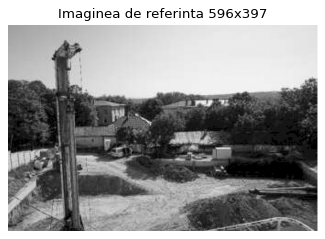

Metode disponibile: ['HARRIS', 'SIFT', 'ORB']
Keypoints per metoda: {'HARRIS': 664, 'SIFT': 2246, 'ORB': 1500}


In [17]:
def load_reference_image(image_path) -> np.ndarray:
    if image_path is None:
        return cv2.cvtColor(skimage_data.astronaut(), cv2.COLOR_RGB2GRAY)
    return load_gray(Path(image_path))


reference_gray = load_reference_image(IMAGE_PATH)
detectors = available_detectors()
reference_features = extract_all_features(detectors, reference_gray)

plt.figure(figsize=(5, 5))
plt.imshow(reference_gray, cmap="gray")
plt.title(f"Imaginea de referinta {reference_gray.shape[1]}x{reference_gray.shape[0]}")
plt.axis("off")
plt.show()
print("Metode disponibile:", detectors)
print("Keypoints per metoda:", {name: len(f.keypoints) for name, f in reference_features.items()})

## == 1a == Imaginea cu keypoints marcate

Cercurile arata scala si linia din cerc orientarea keypoint-ului.

-> Harris da puncte de aceeasi dimensiune (nu e multi-scala)

-> SIFT/KAZE/AKAZE variaza scala

-> ORB/BRISK au zeci de puncte grupate pe textura.

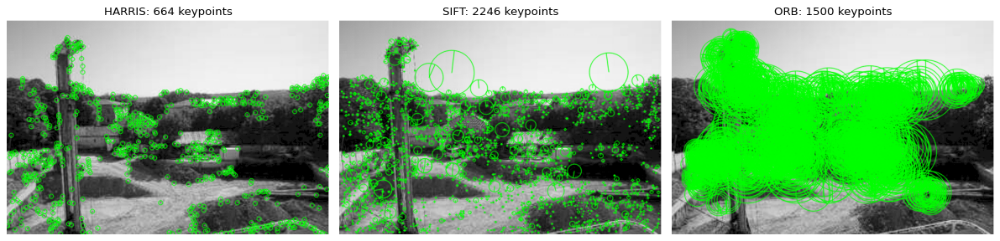

In [18]:
plot_keypoints(reference_gray, reference_features, "1a_keypoints.png")

Concluzie:

HARRIS:
- Cauta strict colturi ascutite printr-o singura fereastra minuscula fara zoom, motiv pentru care gaseste putine puncte si toate au aceeasi marime mica. Asta se intampla pentru ca algoritmul masoara variatia pixelilor la o singura dimensiune fixa si accepta doar schimbarile bruste pe doua directii simultan, respingand orice alta forma

SIFT:
- Analizeaza poza la mai multe niveluri de zoom si detecteaza atat colturi, cat si pete de contrast, obtinand puncte de marimi diferite imprastiate peste tot. Se intampla asta pentru ca isi creeaza mai multe copii micsorate ale pozei si cauta diferente de contrast in fiecare dintre ele, asociind marimea cercului cu nivelul de zoom la care a gasit detaliul

ORB:
- Este rapid si permisiv, ingramadindu-si toate punctele fix pe zonele cu contrast extrem, ceea ce creeaza cercuri dese si suprapuse.Asta se intampla pentru ca ordoneaza punctele strict dupa cat de puternic este contrastul fata de vecini si le pastreaza pe primele din top, chiar daca sunt lipite unul de altul pe aceeasi margine



## == 1b == Compararea metodelor

Imaginea se imparte in 8 x 8 regiuni neintrepatrunse si se numara keypoints in fiecare. total arata cate puncte produce metoda; empty_regions si coeff_variation arata daca punctele sunt grupate (valori mari) sau acopera uniform imaginea (valori mici).

In [19]:
counts_table = pd.DataFrame(
    {"keypoints": {name: len(f.keypoints) for name, f in reference_features.items()}}
)
display(counts_table)

,keypoints
HARRIS,664
SIFT,2246
ORB,1500


plot_region_counts
- transmite dimensiunea imaginii si fictionarul cu punctele detectate de fiecare algoritm
- Imparte imaginea in cele 64 de casute (8 randuri x 8 coloane) si numara cate puncte cheie au cazut in fiecare casuta, separat pentru fiecare algoritm
- fiecare patrat are o culoare proportionala cu numarul de puncte din el si cifra exacta scrisa in interior. Zonele aprinse arata unde s-au ingramadit punctele (de exemplu, pe detalii cu contrast mare), iar zonele intunecate cu 0 arata regiunile complet ignorate (de exemplu, fundalul uniform).

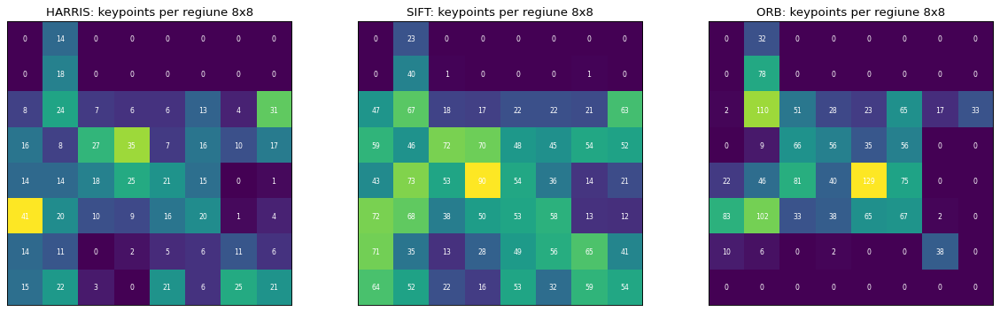

,total,empty_regions,max_in_region,coeff_variation
detector,,,,
HARRIS,664,17,41,0.95
SIFT,2246,12,90,0.72
ORB,1500,32,129,1.40


In [20]:
plot_region_counts(reference_gray.shape, reference_features, "1b_region_counts.png")
display(distribution_table(reference_gray.shape, reference_features))

Concluzii:

- SIFT are acoperire 0.72. Gaseste cele mai multe puncte (2246) si lasa doar 12 patrate goale, adica fix zonele cu cer senin. Asta se intampla pentru ca SIFT cauta atat colturi, cat si pete de contrast la mai multe niveluri de zoom, reusind sa gaseasca repere chiar si in zone mai putin clare, precum iarba sau dealurile din fundal

- ORB ingramadeste punctele intr-un singur loc. Desi are 1500 de puncte, lasa jumatate din poza complet goala (32 de patrate cu 0, inclusiv tot randul de jos) si pune pana la 129 de puncte intr-o singura casuta. Isi consuma toate punctele pe stalp si pe cladirile din centru, ignorand complet zonele mai sterse.

- HARRIS este echilibrat, dar are putine puncte Doar 664 de puncte in total, lasa 17 patrate goale, aproape la fel de putine ca SIFT. Chiar daca este pretentios si accepta doar colturi geometrice autentice, le cauta local pe toata suprafata pozei, asa ca nu le ingramadeste intr-o singura zona ca ORB.

## == 1c == Blur

Se calculeaza keypoints pe fiecare imagine blurata si se potrivesc cu cele ale originalului (brut force, cross-check, knn, test Lowe).

o metoda robusta isi pastreaza numarul de potriviri cand blur-ul creste

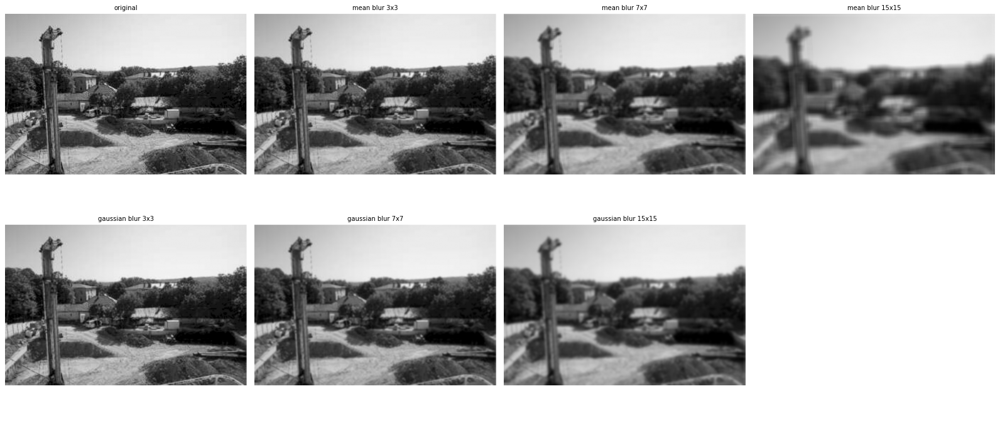

In [21]:
blur_variants = build_blur_variants(reference_gray)
plot_image_grid({"original": reference_gray, **blur_variants}, "1c_blur_variants.png")

blur_variants este un dictionar care contine o eticheta si imaginea noastra

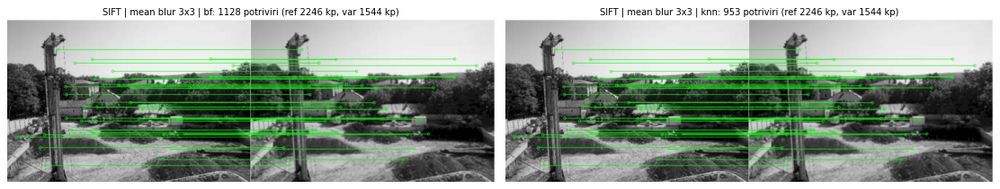

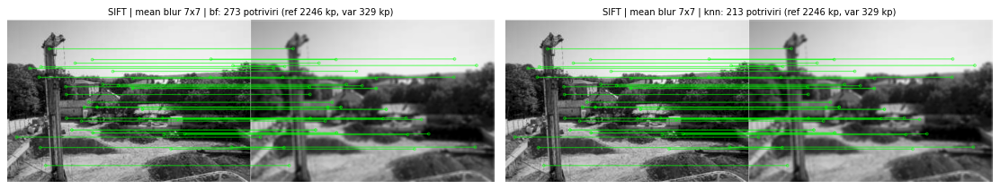

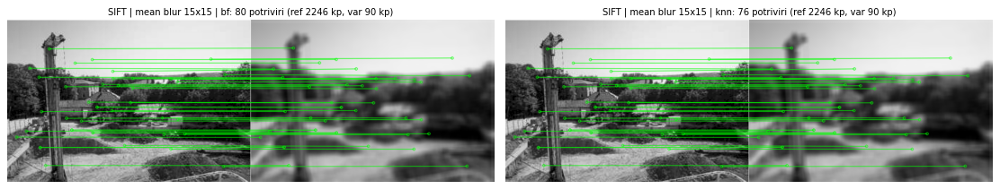

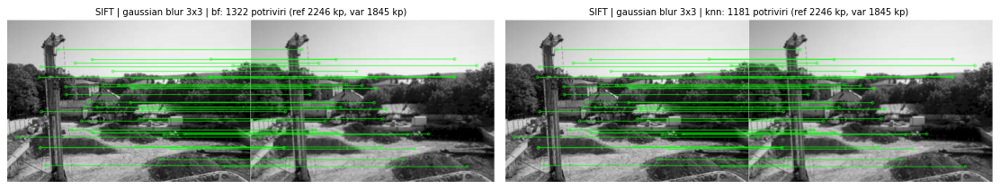

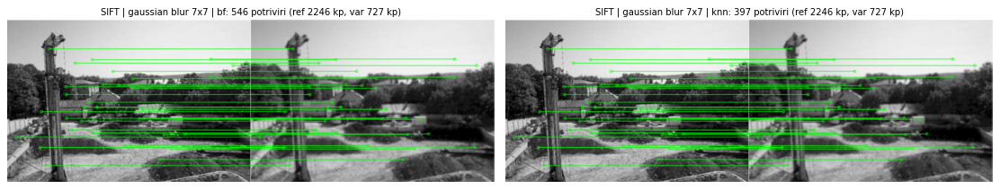

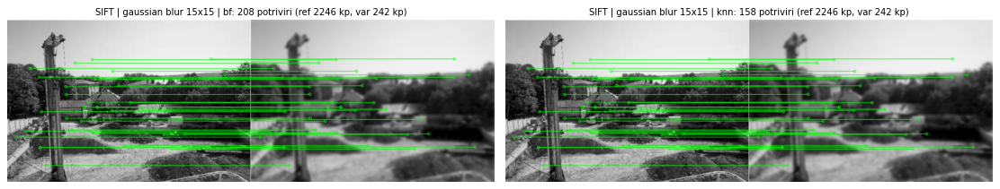

In [22]:
plot_match_gallery(VISUAL_DETECTOR, reference_gray, reference_features[VISUAL_DETECTOR], blur_variants, "1c_matches")

Potriviri brute force (bf):


detector,HARRIS,ORB,SIFT
variant,,,
mean blur 3x3,469,1170,1128
mean blur 7x7,301,581,273
mean blur 15x15,131,103,80
gaussian blur 3x3,502,1214,1322
gaussian blur 7x7,382,979,546
gaussian blur 15x15,222,426,208


Potriviri kNN (knn):


detector,HARRIS,ORB,SIFT
variant,,,
mean blur 3x3,507,1156,953
mean blur 7x7,223,505,213
mean blur 15x15,21,101,76
gaussian blur 3x3,554,1216,1181
gaussian blur 7x7,394,923,397
gaussian blur 15x15,182,410,158


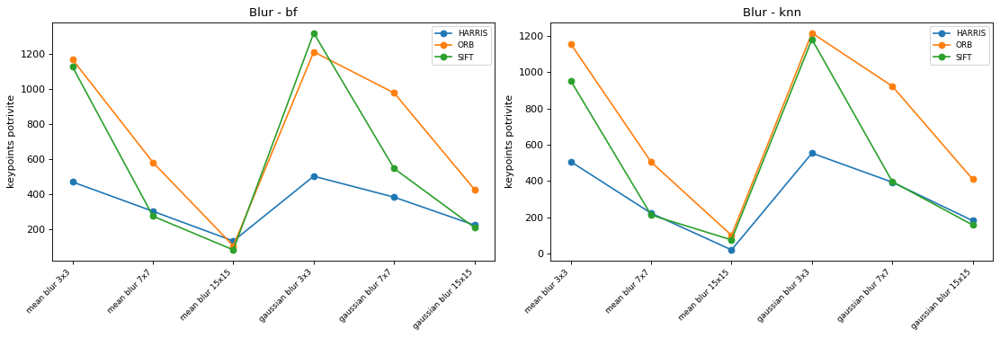

In [23]:
blur_table = evaluate_variants(reference_features, blur_variants)
print("Potriviri brute force (bf):")
display(pivot_matches(blur_table, "bf"))
print("Potriviri kNN (knn):")
display(pivot_matches(blur_table, "knn"))
plot_match_curves(blur_table, "Blur", "1c_blur_curves.png")

Concluzii:
- pe masuyra ce blurul creste, numarul de potriviri scade pentru toti algoritmii
- filtrul gaussian functioneaza mai bine decat cel clasic. Filtrul gaussian acorda ponderea cea mai mare pixelului din centru si o scade treptat spre margini, pastrand astfel mai bine geometria colturilor si a muchiilor. In schimb, filtrul clasic (mean) face o medie plata in care toti vecinii au aceeasi greutate, aplatizand mult mai agresiv contrastul local.

Diferenta dintre algoritmii folositi:
- ORB ramane in top la potriviri deoarece detectorul sau isi concentreaza punctele pe tranzitiile cu cel mai puternic contrast din imagine, precum marginea unui stalp pe fundalul luminos. Chiar si dupa o incetosare puternica, aceasta diferenta majora nu dispare complet, ci doar se estompeaza usor, iar descriptorul binar ramane stabil pentru ca netezeste oricum zona inainte de comparatie.
- SIFT pierde multe puncte la blur puternic deoarece identifica detaliile calculand diferente intre versiuni tot mai incetosate ale aceleiasi imagini. Cand fotografia initiala este deja foarte blurata, detaliile fine lipsesc, iar nivelurile suplimentare aplicate de algoritm ajung sa arate aproape identic, facand ca diferentele sa scada sub pragul de detectie.
- HARRIS gaseste din start mai putine puncte pentru ca valideaza strict colturile autentice, unde intensitatea se schimba brusc pe ambele directii simultan, ignorand petele sau texturile simple. Pe masura ce blurul rotunjeste aceste unghiuri ascutite, gradientii scad rapid si colturile dispar

Diferenta intre metodele de matching:
- Brute-Force gaseste un numar mai mare de potriviri deoarece cauta doar cea mai apropiata pereche reciproca intre cele doua imagini. Totusi, atunci cand poza este incetosata si multe zone ajung sa semene intre ele, aceasta metoda risca sa valideze si asocieri gresite.
- kNN merge mai bine la capitolul precizie pentru ca verifica primii doi cei mai buni candidati pentru fiecare punct si pastreaza potrivirea doar daca primul este net superior celui de-al doilea. Astfel, respinge automat cazurile ambigue create de blur si retine doar corespondentele cu adevarat sigure.


## === 1d === Rotatie

Imaginea originala este rotita cu 15, 45, 90 si 180

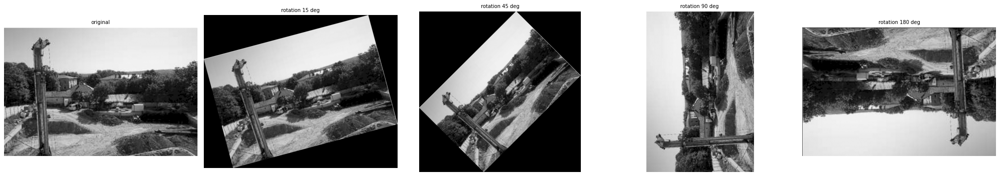

In [24]:
rotation_variants = build_rotation_variants(reference_gray)
plot_image_grid({"original": reference_gray, **rotation_variants}, "1d_rotation_variants.png", columns=5)

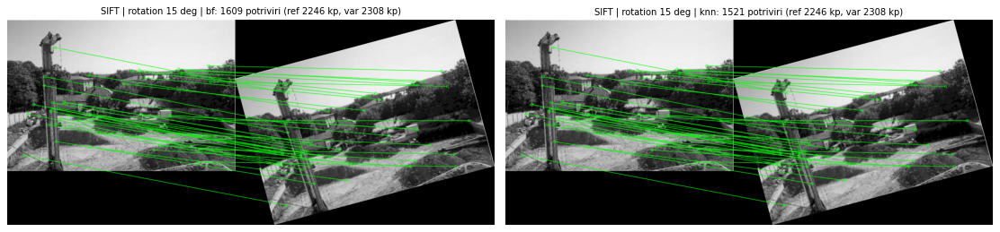

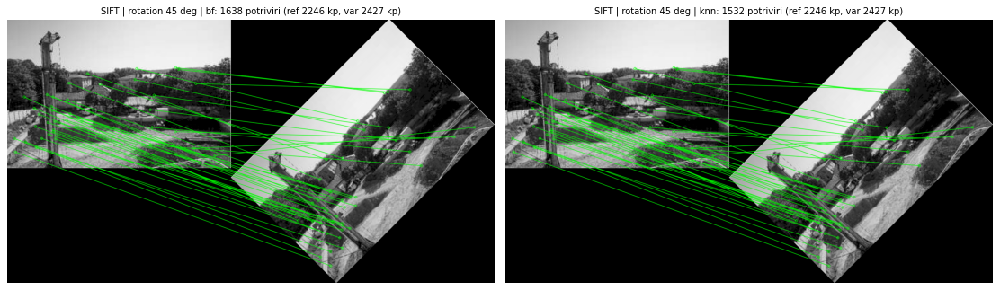

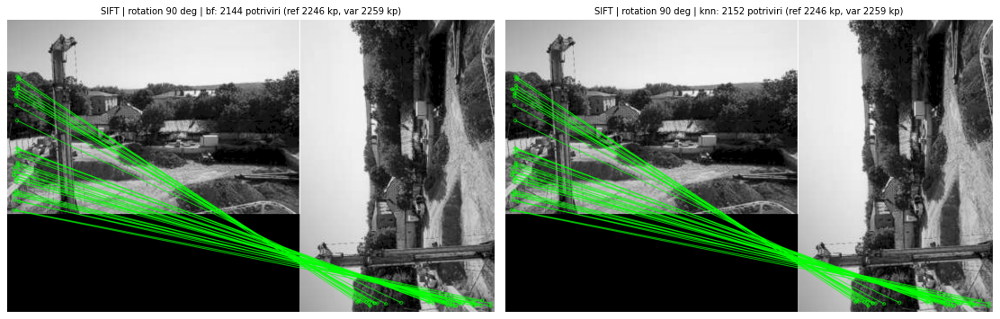

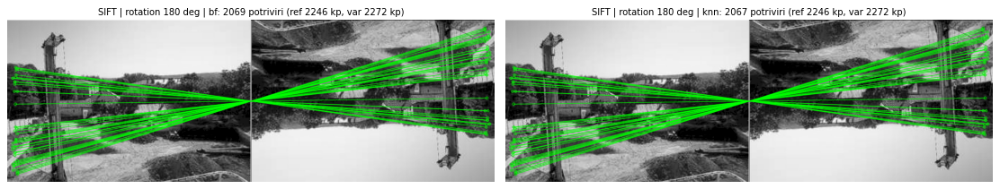

In [25]:
plot_match_gallery(VISUAL_DETECTOR, reference_gray, reference_features[VISUAL_DETECTOR], rotation_variants, "1d_matches")

Potriviri brute force (bf):


detector,HARRIS,ORB,SIFT
variant,,,
rotation 15 deg,164,996,1609
rotation 45 deg,29,980,1638
rotation 90 deg,122,1307,2144
rotation 180 deg,76,1253,2069


Potriviri kNN (knn):


detector,HARRIS,ORB,SIFT
variant,,,
rotation 15 deg,77,950,1521
rotation 45 deg,2,958,1532
rotation 90 deg,0,1312,2152
rotation 180 deg,5,1220,2067


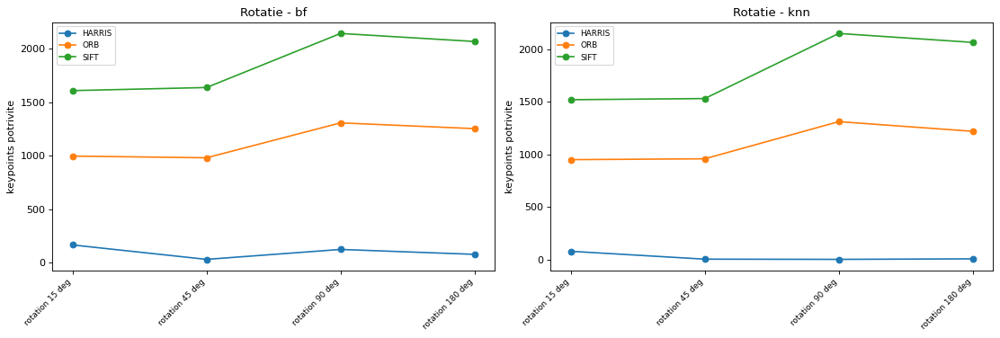

In [26]:
rotation_table = evaluate_variants(reference_features, rotation_variants)
print("Potriviri brute force (bf):")
display(pivot_matches(rotation_table, "bf"))
print("Potriviri kNN (knn):")
display(pivot_matches(rotation_table, "knn"))
plot_match_curves(rotation_table, "Rotatie", "1d_rotation_curves.png")

Concluzii:

Comparatia algoritmilor:
- SIFT obtine cele mai bune rezultate. Algoritmul identifica directia dominanta din jurul fiecarui punct cheie si isi aliniaza descriptorul dupa aceasta, astfel incat amprenta numerica ramane aceeasi indiferent cat de inclinata este imaginea.
- ORB se descurca bine. La fel ca SIFT, isi calculeaza orientarea fiecarui punct in functie de distributia luminozitatii din jur si isi roteste sablonul binar inainte de comparatie, recunoscand usor detaliile chiar si cand poza este intoarsa invers.
- HARRIS nu are un rezultat prea bun. Chiar daca detectorul reuseste sa gaseasca in continuare colturile in imaginea rotita, descriptorul sau compara direct pixelii din jur fara sa tina cont de noul unghi, motiv pentru care valorile nu se mai potrivesc deloc cu cele initiale.

Rezultate unghiuri:
- 90 si 180 produc un rezultat mai bun decat 15 si 45 de grade la SIFT si ORB. La unghiuri drepte, pixelii sunt doar mutati exact pe noua grila fara sa se piarda din claritate, in timp ce la inclinari oblice imaginea se incetoseaza usor din cauza interpolarii, iar marginile negre adaugate in jur introduc colturi false.

Brute force vs KNN
- pentru SIFT si ORB rezultatele sunt similare deoarece descriptorii lor raman foarte clari si usor de recunoscut dupa rotatie.
- la HARRIS, unde BF mai gaseste cateva zeci de potriviri false pe conturul negru al cadrului, in timp ce kNN le filtreaza complet

## == 1e == Zgomot Gaussian

Se adauga zgomot cu sigma = 5, 15, 30, 60.

zgomotul creste numarul de keypoints, dar nu si numarul de potriviri corecte

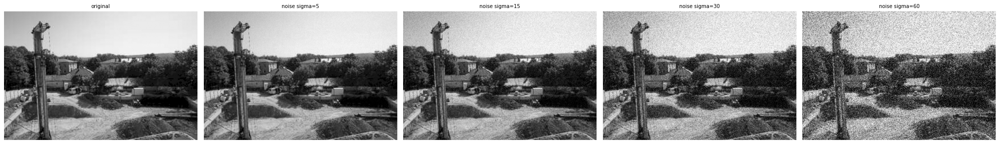

In [27]:
noise_variants = build_noise_variants(reference_gray)
plot_image_grid({"original": reference_gray, **noise_variants}, "1e_noise_variants.png", columns=5)

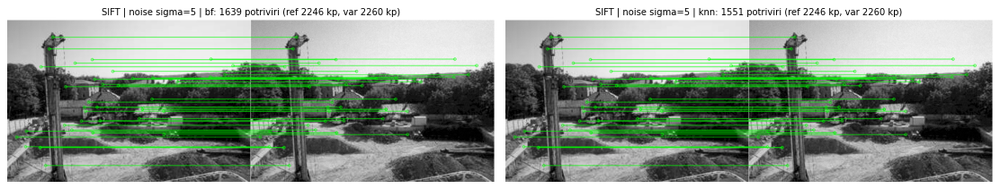

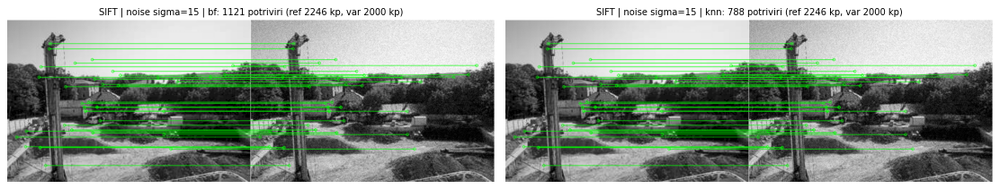

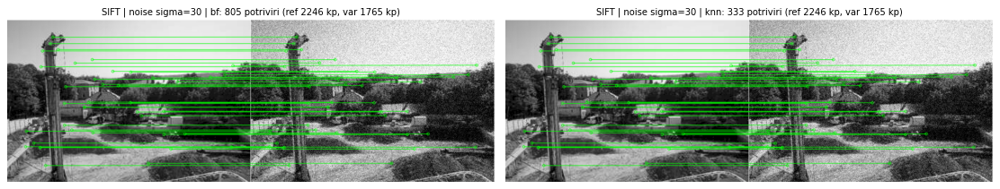

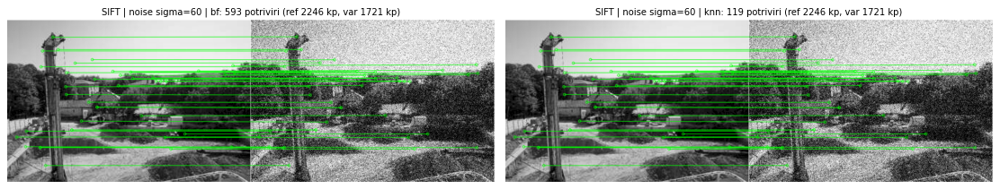

In [28]:
plot_match_gallery(VISUAL_DETECTOR, reference_gray, reference_features[VISUAL_DETECTOR], noise_variants, "1e_matches")

Potriviri brute force (bf):


detector,HARRIS,ORB,SIFT
variant,,,
noise sigma=5,588,1317,1639
noise sigma=15,589,1158,1121
noise sigma=30,536,938,805
noise sigma=60,464,641,593


Potriviri kNN (knn):


detector,HARRIS,ORB,SIFT
variant,,,
noise sigma=5,607,1323,1551
noise sigma=15,548,1084,788
noise sigma=30,409,788,333
noise sigma=60,140,380,119


Numar de keypoints pe imaginea zgomotoasa (kp_variant):


detector,HARRIS,ORB,SIFT
variant,,,
noise sigma=5,687,1500,2260
noise sigma=15,1584,1500,2000
noise sigma=30,2000,1500,1765
noise sigma=60,2000,1500,1721


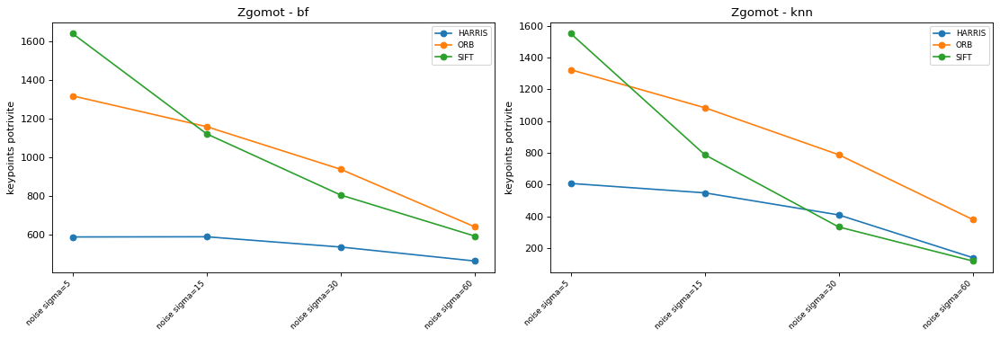

In [29]:
noise_table = evaluate_variants(reference_features, noise_variants)
print("Potriviri brute force (bf):")
display(pivot_matches(noise_table, "bf"))
print("Potriviri kNN (knn):")
display(pivot_matches(noise_table, "knn"))
print("Numar de keypoints pe imaginea zgomotoasa (kp_variant):")
display(noise_table.pivot(index="variant", columns="detector", values="kp_variant").loc[noise_table["variant"].unique()])
plot_match_curves(noise_table, "Zgomot", "1e_noise_curves.png")

Concluzii:

Algoritmi:
- ORB. Cand zgomotul devine puternic (la sigma=60), ORB ramane pe primul loc cu 380 de potriviri pe kNN, in timp ce ceilalti algoritmi scad drastic. Motivul este foarte practic: inainte sa isi calculeze amprenta numerica pentru un punct, ORB aplica automat o mica netezire peste zona din jurul lui. Practic, isi sterge singur o buna parte din zgomot inainte sa compare pixelii, asa ca reuseste sa recunoasca in continuare detaliile importante
- SIFT. La sigma=5 are cele mai multe potriviri (1551 pe kNN), insa la sigma=60 pica la doar 119, chiar daca detecteaza in continuare peste 1700 de puncte. Asta se intampla pentru ca SIFT este foarte atent la detalii fine si calculeaza directia in care se schimba luminozitatea in jurul fiecarui punct. Cand adaugi mult zgomot, valorile pixelilor sar haotic in sus si in jos, ceea ce ii da peste cap calculele si il face sa creeze o amprenta diferita fata de cea din poza curata
- HARRIS. pe masura ce creste zgomotul, numarul de puncte gasite de HARRIS explodeaza de la 687 pana la limita maxima de 2000, dar potrivirile reale pe kNN scad la 140. HARRIS cauta schimbari bruste intre pixeli vecini ca sa identifice colturi. Un fir de zgomot alb aparut din senin pe un fundal intunecat arata exact ca un colt foarte ascutit, asa ca zgomotul pacaleste detectorul sa umple poza cu puncte false care nu existau in fotografia originala

---
# == Ex 2 ==

Pregatirea setului

In [30]:
dataset_root = prepare_dataset(DATASET_DIR, DATASET_ZIP, WORK_DIR, SEED)

[30]
2m
$0
train_samples = load_split(dataset_root / "train")
test_samples = load_split(dataset_root / "test")
class_labels = sorted({s.label for s in train_samples} | {s.label for s in test_samples})
print(f"Train: {len(train_samples)} imagini | Test: {len(test_samples)} imagini | Clase: {class_labels}")
print("Distributie train:", dict(Counter(s.label for s in train_samples)))
print("Distributie test:", dict(Counter(s.label for s in test_samples)))
plot_sample_grid(train_samples + test_samples, "2_dataset_overview.png", columns=6)

Se foloseste arhiva: /content/IIT_DB_selectie.ZIP
Train: 400 imagini | Test: 83 imagini | Clase: ['BCU', 'BVD_COPOU', 'UAIC']
Distributie train: {'BCU': 70, 'BVD_COPOU': 130, 'UAIC': 200}
Distributie test: {'BCU': 15, 'BVD_COPOU': 27, 'UAIC': 41}


## == 2a == Keypoints si descriptori pentru toate imaginile, cu mai multe metode

Pentru fiecare metoda se extrag keypoints si descriptori din toate imaginile.

In [31]:
dataset_features = {
    detector: (extract_split(train_samples, detector), extract_split(test_samples, detector))
    for detector in detectors
}
display(features_statistics(dataset_features))

,images,with_keypoints,mean_keypoints,descriptor_dim,descriptor_dtype
detector,,,,,
HARRIS,483,483,814.2,128,float32
SIFT,483,483,1771.2,128,float32
ORB,483,483,1452.0,32,uint8


- Numar total imagini procesate
- Numar imagini care au keypoints
- media numarului de keypoints gasite
- dimensiunea descriptorului
- tipul descriptorului

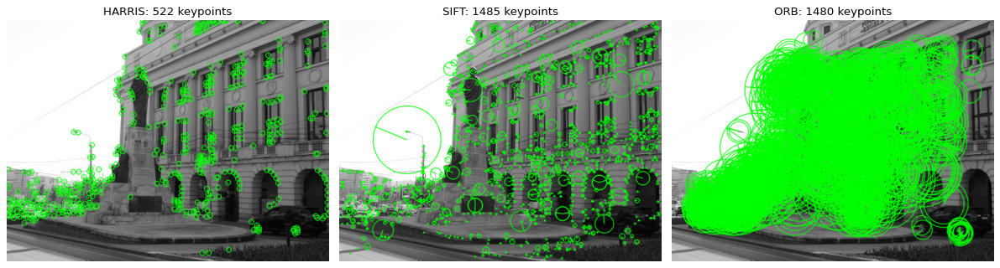

In [32]:
train_example_features = {d: dataset_features[d][0][0] for d in detectors if dataset_features[d][0][0] is not None}
plot_keypoints(train_samples[0].gray, train_example_features, "2a_keypoints_train_example.png")

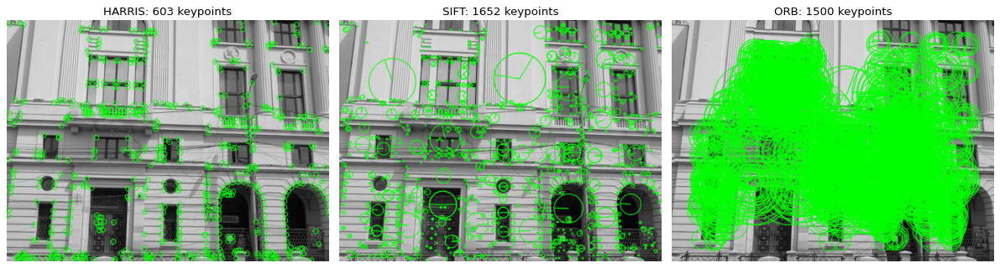

In [33]:
test_example_features = {d: dataset_features[d][1][0] for d in detectors if dataset_features[d][1][0] is not None}
plot_keypoints(test_samples[0].gray, test_example_features, "2a_keypoints_test_example.png")

## == 2b == Potrivirea fiecarei imagini test cu toate imaginile train

Pentru metoda din VISUAL_DETECTOR se construieste matricea cu numarul de potriviri, pentru BF si pentru KNN. Celula luminoasa dintr-un rand este imaginea train cea mai asemanatoare. Se afiseaza si tabelul numeric pentru kNN.

In [34]:
score_cache = {}


def get_score_matrix(detector: str, method: str) -> np.ndarray:
    key = (detector, method)
    if key not in score_cache:
        train_features, test_features = dataset_features[detector]
        score_cache[key] = build_score_matrix(test_features, train_features, method)
    return score_cache[key]

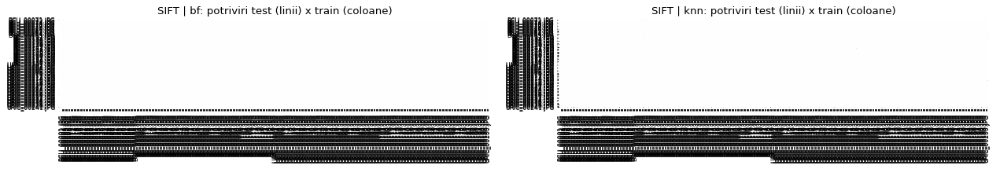

,BCU_00001.JPG,BCU_00002.JPG,BCU_00003.JPG,BCU_00004.JPG,BCU_00005.JPG,BCU_00006.JPG,BCU_00007.JPG,BCU_00008.JPG,BCU_00009.JPG,BCU_00010.JPG,...,UAIC_00191.JPG,UAIC_00192.JPG,UAIC_00193.JPG,UAIC_00194.JPG,UAIC_00195.JPG,UAIC_00196.JPG,UAIC_00197.JPG,UAIC_00198.JPG,UAIC_00199.JPG,UAIC_00200.JPG
BCU_00071.JPG,28.0,28.0,31.0,33.0,26.0,19.0,15.0,16.0,24.0,26.0,...,15.0,14.0,17.0,32.0,32.0,22.0,35.0,35.0,22.0,12.0
BCU_00072.JPG,22.0,29.0,41.0,25.0,23.0,33.0,13.0,16.0,18.0,34.0,...,16.0,14.0,32.0,17.0,23.0,27.0,28.0,22.0,20.0,24.0
BCU_00073.JPG,38.0,30.0,52.0,38.0,19.0,16.0,10.0,9.0,10.0,26.0,...,14.0,19.0,21.0,20.0,27.0,22.0,32.0,37.0,19.0,9.0
BCU_00074.JPG,36.0,33.0,23.0,30.0,24.0,25.0,19.0,23.0,13.0,26.0,...,8.0,14.0,16.0,22.0,10.0,18.0,26.0,20.0,22.0,15.0
BCU_00075.JPG,26.0,20.0,23.0,23.0,11.0,23.0,16.0,21.0,15.0,27.0,...,16.0,14.0,20.0,12.0,24.0,22.0,24.0,26.0,26.0,16.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UAIC_00237.JPG,6.0,7.0,14.0,23.0,11.0,10.0,10.0,12.0,11.0,16.0,...,20.0,14.0,13.0,10.0,15.0,7.0,14.0,13.0,18.0,10.0
UAIC_00238.JPG,15.0,12.0,6.0,19.0,11.0,9.0,9.0,9.0,14.0,17.0,...,13.0,11.0,18.0,21.0,13.0,9.0,13.0,19.0,16.0,8.0
UAIC_00239.JPG,17.0,14.0,9.0,31.0,25.0,21.0,10.0,13.0,18.0,17.0,...,17.0,26.0,16.0,17.0,13.0,11.0,25.0,25.0,18.0,16.0
UAIC_00240.JPG,14.0,12.0,21.0,26.0,21.0,16.0,18.0,17.0,18.0,17.0,...,12.0,23.0,12.0,10.0,15.0,13.0,18.0,28.0,15.0,16.0


In [35]:
visual_train_features, visual_test_features = dataset_features[VISUAL_DETECTOR]
score_by_method = {method: get_score_matrix(VISUAL_DETECTOR, method) for method in MATCHING_METHODS}

plot_score_matrices(score_by_method, train_samples, test_samples, VISUAL_DETECTOR, "2b_score_matrices.png")
score_frame = pd.DataFrame(
    score_by_method["knn"],
    index=[s.name for s in test_samples],
    columns=[s.name for s in train_samples],
)
display(score_frame)

## == 2c == Multimea imaginilor train cu numar maxim de potriviri

tabelul arata scorul maxim, marimea multimii si numele imaginilor, mai jos, potrivirile desenate intre o imagine test si imaginea train castigatoare. Pentru fiecare imagine de test am luat randul ei din matricea de potriviri si am cautat valoarea maxima. Multimea ceruta in 2c este formata din toate imaginile de train care ating acea valoare. Daca maximul este 0, multimea este goala, pentru ca nu exista nicio potrivire reala. Am afisat multimea ca tabel si am desenat potrivirile pentru castigator ca verificare vizuala.

In [36]:

for method in MATCHING_METHODS_LOCAL:
    print(f"Max potrivire ({VISUAL_DETECTOR_LOCAL}, {method}):")
    display(describe_top_sets(score_by_method[method], train_samples, test_samples))

Max potrivire (SIFT, bf):


,test_image,best_score,set_size,train_images_with_max
0,BCU_00071.JPG,861,1,[BCU_00070.JPG]
1,BCU_00072.JPG,641,1,[BCU_00069.JPG]
2,BCU_00073.JPG,418,1,[UAIC_00028.JPG]
3,BCU_00074.JPG,623,1,[UAIC_00027.JPG]
4,BCU_00075.JPG,552,1,[UAIC_00002.JPG]
...,...,...,...,...
78,UAIC_00237.JPG,1110,1,[UAIC_00027.JPG]
79,UAIC_00238.JPG,1183,1,[UAIC_00027.JPG]
80,UAIC_00239.JPG,1204,1,[UAIC_00027.JPG]
81,UAIC_00240.JPG,1226,1,[UAIC_00027.JPG]


Max potrivire (SIFT, knn):


,test_image,best_score,set_size,train_images_with_max
0,BCU_00071.JPG,731,1,[BCU_00070.JPG]
1,BCU_00072.JPG,317,1,[BCU_00069.JPG]
2,BCU_00073.JPG,192,1,[BCU_00070.JPG]
3,BCU_00074.JPG,46,1,[BC_00119.JPG]
4,BCU_00075.JPG,45,1,[BC_00022.JPG]
...,...,...,...,...
78,UAIC_00237.JPG,35,1,[UAIC_00177.JPG]
79,UAIC_00238.JPG,25,1,[UAIC_00134.JPG]
80,UAIC_00239.JPG,31,2,"[BCU_00004.JPG, BCU_00032.JPG]"
81,UAIC_00240.JPG,34,1,[BCU_00032.JPG]


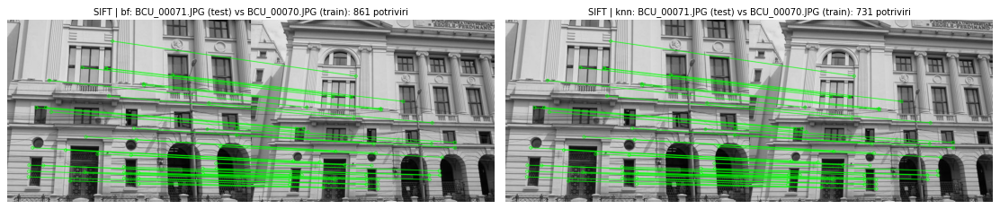

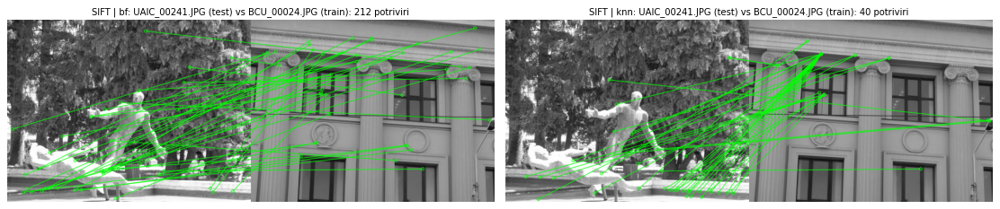

In [37]:
for test_index in (0, len(test_samples) - 1):
    winners = top_train_indices(score_by_method["knn"][test_index])
    if winners:
        plot_best_match(
            test_samples[test_index],
            visual_test_features[test_index],
            train_samples[winners[0]],
            visual_train_features[winners[0]],
            VISUAL_DETECTOR,
            f"2c_best_match_{test_index}.png",
        )

## == 2d == Atribuirea etichetei

- Un singur candidat are eticheta lui.
- Mai multi candidati se va vota( se numara etichetele candidatilor)
- Paritate se afiseaza numele imaginii test si se alege aleator

Prima celula testeaza vote_label pe cazuri construite, a doua clasifica imaginile test cu ambele proceduri.

In [38]:
vote_rng = random.Random(SEED)
print("Majoritate ->", vote_label(["loc_A", "loc_A", "loc_B"], vote_rng, "exemplu_majoritate.jpg"))
print("Paritate   ->", vote_label(["loc_A", "loc_B"], vote_rng, "exemplu_paritate.jpg"))

Majoritate -> loc_A
PARITATE pentru imaginea test exemplu_paritate.jpg: etichete la egalitate ['loc_A', 'loc_B'], alegere aleatoare
Paritate   -> loc_B


In [39]:
for method in MATCHING_METHODS:
    predictions = predict_all(score_by_method[method], train_samples, test_samples, SEED)
    print(f"Predictii {VISUAL_DETECTOR} + {method}:")
    display(predictions_table(test_samples, predictions))

PARITATE pentru imaginea test BCU_00077.JPG: etichete la egalitate ['BVD_COPOU', 'UAIC'], alegere aleatoare
Predictii SIFT + bf:


,test_image,true_label,predicted,correct
0,BCU_00071.JPG,BCU,BCU,True
1,BCU_00072.JPG,BCU,BCU,True
2,BCU_00073.JPG,BCU,UAIC,False
3,BCU_00074.JPG,BCU,UAIC,False
4,BCU_00075.JPG,BCU,UAIC,False
...,...,...,...,...
78,UAIC_00237.JPG,UAIC,UAIC,True
79,UAIC_00238.JPG,UAIC,UAIC,True
80,UAIC_00239.JPG,UAIC,UAIC,True
81,UAIC_00240.JPG,UAIC,UAIC,True


PARITATE pentru imaginea test BC_00145.JPG: etichete la egalitate ['BVD_COPOU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test BC_00152.JPG: etichete la egalitate ['BCU', 'BVD_COPOU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test BC_00153.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
Predictii SIFT + knn:


,test_image,true_label,predicted,correct
0,BCU_00071.JPG,BCU,BCU,True
1,BCU_00072.JPG,BCU,BCU,True
2,BCU_00073.JPG,BCU,BCU,True
3,BCU_00074.JPG,BCU,BVD_COPOU,False
4,BCU_00075.JPG,BCU,BVD_COPOU,False
...,...,...,...,...
78,UAIC_00237.JPG,UAIC,UAIC,True
79,UAIC_00238.JPG,UAIC,UAIC,True
80,UAIC_00239.JPG,UAIC,BCU,False
81,UAIC_00240.JPG,UAIC,BCU,False


## == 2e == Acuratete si matrice de confuzie

Pentru fiecare combinatie se calculeaza predictiile, acuratetea si matricea de confuzie

In [40]:
true_labels = [sample.label for sample in test_samples]
results = {}
for detector in detectors:
    train_features, test_features = dataset_features[detector]
    for method in MATCHING_METHODS:
        scores = get_score_matrix(detector, method)
        predicted = predict_all(scores, train_samples, test_samples, SEED)
        results[(detector, method)] = evaluate_predictions(true_labels, predicted, class_labels)

accuracy_table = pd.DataFrame(
    {method: {detector: results[(detector, method)][1] for detector in detectors} for method in MATCHING_METHODS}
).round(3)
display(accuracy_table)

PARITATE pentru imaginea test BC_00132.JPG: etichete la egalitate ['BVD_COPOU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test BC_00134.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test BC_00155.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test UAIC_00209.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test UAIC_00226.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test UAIC_00232.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test UAIC_00236.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test UAIC_00239.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test UAIC_00240.JPG: etichete la egalitate ['BCU', 'UAIC'], alegere aleatoare
PARITATE pentru imaginea test BCU_00077.JPG: etichete la egalitate ['BVD_

,bf,knn
HARRIS,0.590,0.506
SIFT,0.602,0.651
ORB,0.518,0.590


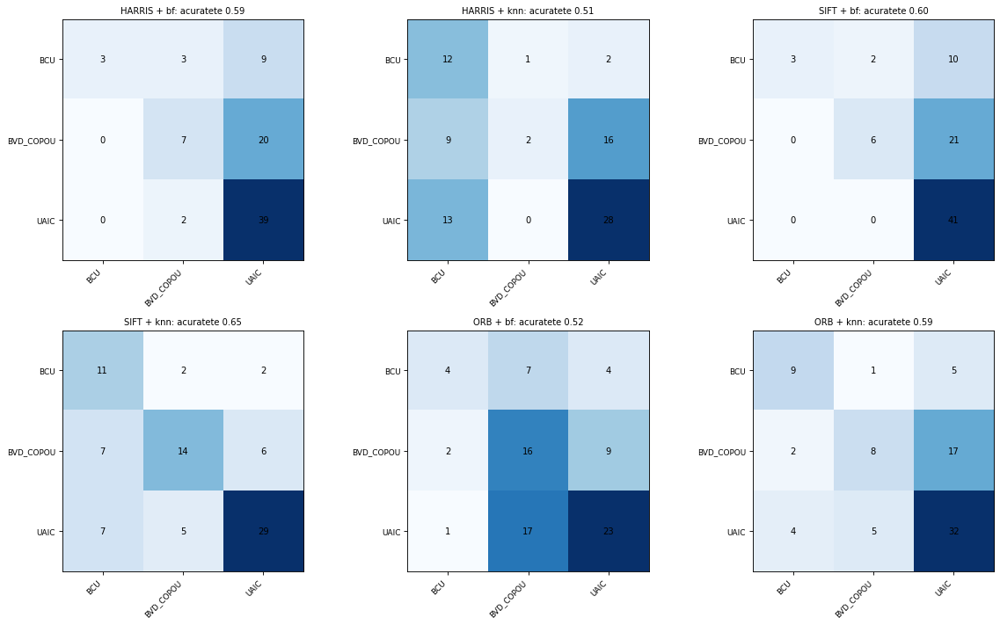

Cea mai bună combinatie: SIFT + knn, acuratete 0.651


,BCU,BVD_COPOU,UAIC
BCU,11,2,2
BVD_COPOU,7,14,6
UAIC,7,5,29


In [41]:
plot_confusion_matrices(results, class_labels, "2e_confusion_matrices.png")
best_detector, best_method = max(results, key=lambda key: results[key][1])
print(f"Cea mai bună combinatie: {best_detector} + {best_method}, acuratete {results[(best_detector, best_method)][1]:.3f}")
display(pd.DataFrame(results[(best_detector, best_method)][0], index=class_labels, columns=class_labels))

In [42]:
blank_image = np.full((200, 200), 128, dtype=np.uint8)
low_contrast = np.full((200, 200), 128, dtype=np.uint8)
for center in ((50, 60), (120, 90), (150, 150), (70, 140)):
    cv2.circle(low_contrast, center, 12, 134, -1)
low_contrast = cv2.GaussianBlur(low_contrast, (5, 5), 0)

print("Imagine uniforma:")
for detector in detectors:
    features, level = extract_with_level(detector, blank_image)
    print(f"  {detector}: {'fara keypoints' if features is None else f'{len(features.keypoints)} keypoints la nivelul {level}'}")

print("Imagine cu contrast mic:")
for detector in detectors:
    features, level = extract_with_level(detector, low_contrast)
    print(f"  {detector}: {'fara keypoints' if features is None else f'{len(features.keypoints)} keypoints la nivelul {level}'}")

blank_scores = build_score_matrix([None], visual_train_features, "bf")
print("Predictie pentru test fara keypoints:", predict_label(blank_scores[0], train_samples, "imagine_uniforma.jpg", random.Random(SEED)))

Imagine uniforma:
  HARRIS: fara keypoints
  SIFT: fara keypoints
  ORB: fara keypoints
Imagine cu contrast mic:
  HARRIS: fara keypoints
  SIFT: 8 keypoints la nivelul 2
  ORB: 45 keypoints la nivelul 3
imagine_uniforma.jpg: fara keypoints sau fara potriviri, eticheta aleatoare
Predictie pentru test fara keypoints: BVD_COPOU
